<a href="https://colab.research.google.com/github/YosepAI/TP-Optimisation/blob/master/lab3_etudiant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 3 — Comparaison des méthodes de descente de gradient
**Méthodes numériques pour les ingénieurs**

**Objectif :** comparer la descente de gradient complète (*batch*), stochastique (*SGD*) et par mini-lots (*mini-batch*) : vitesse, stabilité et trajectoire.

**Convention :** on utilise deux paramètres **séparés** `theta0` (biais) et `theta1` (pente) et deux dérivées `d0`, `d1` (pas de vecteur de paramètres ou de gradient). `x_data` et `y_data` restent des tableaux NumPy pour représenter les observations.

**Pour toutes les méthodes :** une **époque** signifie avoir parcouru l'ensemble des observations une fois. Les comparaisons principales utilisent un coût *complet* évalué sur toutes les données à la fin de chaque époque. Les coûts intermédiaires sont enregistrés séparément pour visualiser les fluctuations.

**Version : étudiant — cellules à compléter**

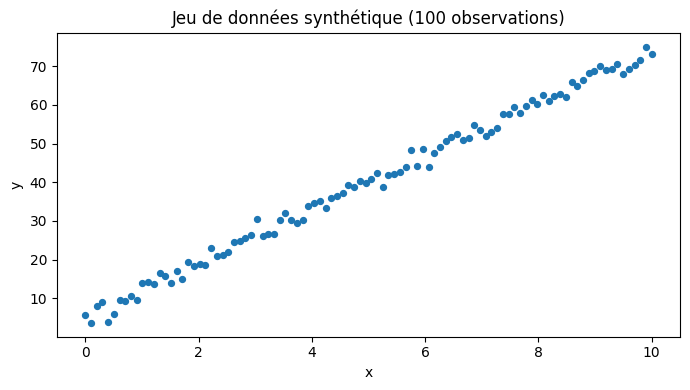

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
m = 100
x_data = np.linspace(0, 10, m)
y_data = 5 + 7*x_data + rng.normal(0, 2, size=m)

plt.figure(figsize=(7, 4))
plt.scatter(x_data, y_data, s=18)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Jeu de données synthétique (100 observations)")
plt.tight_layout()
plt.show()

## 1. Descente de gradient complète (Batch Gradient Descent)

**Questions du PDF :** définir le modèle $\hat y=\theta_0+\theta_1x$, le coût $J=\frac1{2m}\sum_i(y_i-\hat y_i)^2$, initialiser les paramètres et implémenter la descente de gradient. Tracer le coût puis trois droites de régression : initiale, à mi-parcours, finale.

$$\frac{\partial J}{\partial\theta_0}=\frac1m\sum_i(\hat y_i-y_i),\qquad \frac{\partial J}{\partial\theta_1}=\frac1m\sum_i(\hat y_i-y_i)x_i.$$

La méthode complète effectue **une mise à jour par époque**, à partir des *m* observations.

In [2]:
# TODO : implémenter le modèle linéaire, le coût et les deux dérivées.
def predire_lineaire(x, theta0, theta1):
    return theta0 + theta1*x


def cout_lineaire(theta0, theta1):
    # TODO : retourner un seul nombre, J = moyenne(erreurs**2)/2
    erreur = predire_lineaire(x_data, theta0, theta1) - y_data
    return np.mean(erreur**2)/2


def gradients_complets(theta0, theta1):
    # TODO : calculer d0 et d1 sur TOUTES les observations
    # TODO : retourner deux nombres : d0, d1
    d0, d1 = 0, 0
    for i in range(1,99):
      d0 += predire_lineaire(x_data[i],theta0,theta1) - y_data[i]
      d1 += (predire_lineaire(x_data[i],theta0,theta1) - y_data[i])*x_data[i]
    return d0/m, d1/m


print("Coût initial :", cout_lineaire(0, 0))
print("Dérivées initiales :", gradients_complets(0, 0))

Coût initial : 1000.4757450382392
Dérivées initiales : (np.float64(-39.1114760165444), np.float64(-250.97684472871208))


In [3]:
# TODO : une seule mise à jour après calcul des deux dérivées sur toutes les données.
def descente_complete(theta0_init, theta1_init, learning_rate, n_epoques):
    theta0, theta1 = float(theta0_init), float(theta1_init)
    historique_theta = [(theta0, theta1)]
    historique_cout = [cout_lineaire(theta0, theta1)]
    for epoque in range(n_epoques):
        # TODO 1 : calculer d0 et d1 AVANT les mises à jour
        d0, d1 = gradients_complets(theta0,theta1)
        # TODO 2 : mettre à jour theta0 et theta1 séparément
        theta0 = theta0 - learning_rate * d0
        theta1 = theta1 - learning_rate * d1
        # TODO 3 : enregistrer (theta0, theta1) et le coût
        historique_theta.append((theta0, theta1))
        historique_cout.append(cout_lineaire(theta0, theta1))
    return theta0, theta1, historique_theta, historique_cout


eta = 0.01
n_epoques = 80
theta0_batch, theta1_batch, trajectoire_batch, couts_batch = descente_complete(0, 0, eta, n_epoques)
print("Batch :", theta0_batch, theta1_batch, "— coût final :", couts_batch[-1])

Batch : 1.8585351575145677 7.445539594041509 — coût final : 2.686696634086238


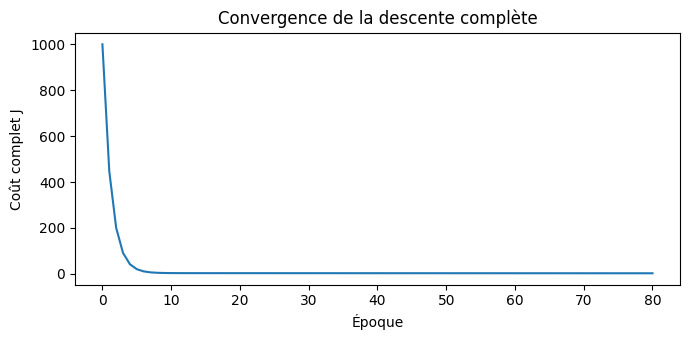

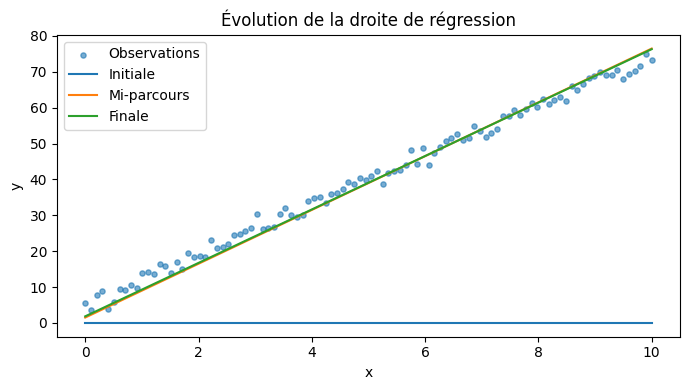

In [4]:
plt.figure(figsize=(7, 3.5))
plt.plot(couts_batch)
plt.xlabel("Époque")
plt.ylabel("Coût complet J")
plt.title("Convergence de la descente complète")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(x_data, y_data, s=14, alpha=0.6, label="Observations")
for i, etiquette in [(0, "Initiale"), (len(trajectoire_batch)//2, "Mi-parcours"), (-1, "Finale")]:
    t0, t1 = trajectoire_batch[i]
    plt.plot(x_data, predire_lineaire(x_data, t0, t1), label=etiquette)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Évolution de la droite de régression")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Descente de gradient stochastique (SGD)

**Questions du PDF :** mettre à jour les paramètres après **chaque observation**, essayer différents taux d'apprentissage, tracer le coût et comparer avec la descente complète.

Pour une observation $(x_i,y_i)$ : $e_i=\hat y_i-y_i$, puis $d_0=e_i$ et $d_1=e_ix_i$.

**Consigne :** mélanger l'ordre des observations à chaque époque. Pour comparer les méthodes, calculer le coût sur les **100 observations** en fin d'époque (et non seulement sur le dernier exemple).

In [5]:
# TODO : SGD — une mise à jour pour chaque observation.
def descente_stochastique(theta0_init, theta1_init, learning_rate, n_epoques, graine=42):
    theta0, theta1 = float(theta0_init), float(theta1_init)
    generateur = np.random.default_rng(graine)
    historique_theta = [(theta0, theta1)]
    historique_cout = [cout_lineaire(theta0, theta1)]
    couts_mises_a_jour = []
    for epoque in range(n_epoques):
        ordre = generateur.permutation(m)
        for i in ordre:
            # TODO 1 : calculer l'erreur de l'observation i
            erreur = (theta0 + theta1 * x_data[i]) - y_data[i]
            # TODO 2 : calculer d0 et d1 à partir de CETTE observation
            d0 = erreur
            d1 = erreur * x_data[i]
            # TODO 3 : mettre à jour theta0 et theta1 séparément
            theta0 = theta0 - learning_rate * d0
            theta1 = theta1 - learning_rate * d1
            # TODO 4 : conserver le coût complet après la mise à jour
            cout_actuel = cout_lineaire(theta0, theta1)
            couts_mises_a_jour.append(cout_actuel)
        # TODO 5 : conserver les paramètres et le coût complet en fin d'époque
        historique_theta.append((theta0, theta1))
        historique_cout.append(cout_lineaire(theta0, theta1))
    return theta0, theta1, historique_theta, historique_cout, couts_mises_a_jour


theta0_sgd, theta1_sgd, trajectoire_sgd, couts_sgd, couts_sgd_updates = descente_stochastique(0, 0, 0.01, n_epoques)
print("SGD :", theta0_sgd, theta1_sgd, "— coût final :", couts_sgd[-1])

SGD : 5.272904040875597 6.758343099747248 — coût final : 1.618727892350026


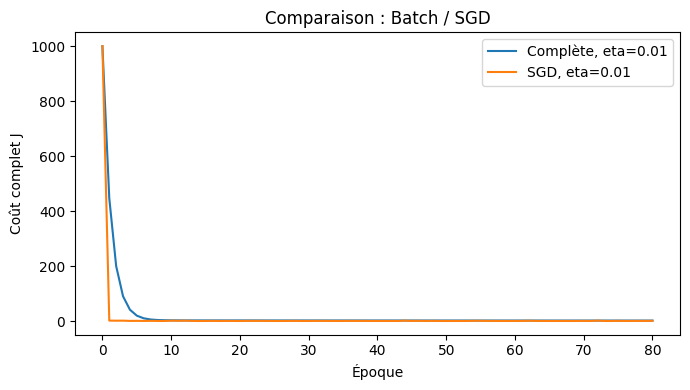

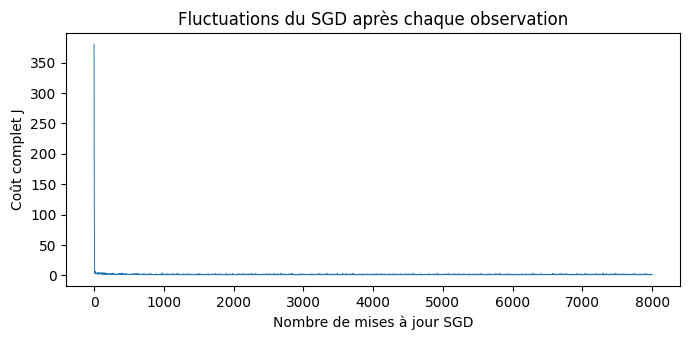

In [6]:
plt.figure(figsize=(7, 4))
plt.plot(couts_batch, label="Complète, eta=0.01")
plt.plot(couts_sgd, label="SGD, eta=0.01")
plt.xlabel("Époque")
plt.ylabel("Coût complet J")
plt.title("Comparaison : Batch / SGD")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3.5))
plt.plot(couts_sgd_updates, linewidth=0.7)
plt.xlabel("Nombre de mises à jour SGD")
plt.ylabel("Coût complet J")
plt.title("Fluctuations du SGD après chaque observation")
plt.tight_layout()
plt.show()

SGD eta=0.0001 : J final=2.6574
SGD eta=0.0005 : J final=1.4675
SGD eta=0.001 : J final=1.2068


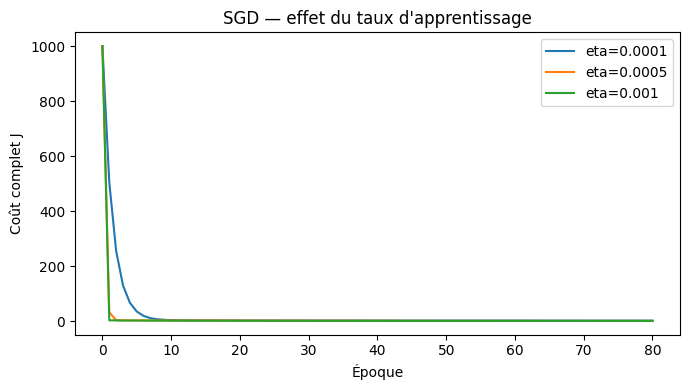

In [7]:
taux_sgd = [0.0001, 0.0005, 0.001]
plt.figure(figsize=(7, 4))
for eta_test in taux_sgd:
    # TODO : exécuter le SGD pour chaque taux d'apprentissage
    t0, t1, trajet, couts, couts_updates = descente_stochastique(0, 0, eta_test, n_epoques)
    # TODO : tracer le coût complet par époque
    plt.plot(couts, label=f"eta={eta_test}")
    print(f"SGD eta={eta_test} : J final={couts[-1]:.4f}")
plt.xlabel("Époque")
plt.ylabel("Coût complet J")
plt.title("SGD — effet du taux d'apprentissage")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Descente de gradient par mini-lots (Mini-Batch)

**Questions du PDF :** effectuer les mises à jour sur des groupes aléatoires de **16, 32 ou 64 observations**, comparer les coûts par époque et les fluctuations après chaque mise à jour, puis superposer les trois méthodes.

**Consigne :** chaque dérivée est une moyenne calculée sur le mini-lot courant. Le dernier mini-lot peut être plus petit que les autres.

In [8]:
# TODO : une mise à jour après chaque mini-lot aléatoire.
def descente_mini_lots(theta0_init, theta1_init, learning_rate, n_epoques, taille_lot, graine=42):
    theta0, theta1 = float(theta0_init), float(theta1_init)
    if not (1 <= taille_lot <= m):
        raise ValueError("taille_lot doit être comprise entre 1 et m")
    generateur = np.random.default_rng(graine)
    historique_theta = [(theta0, theta1)]
    historique_cout = [cout_lineaire(theta0, theta1)]
    couts_mises_a_jour = []
    for epoque in range(n_epoques):
        ordre = generateur.permutation(m)
        for debut in range(0, m, taille_lot):
            # TODO 1 : calculer les erreurs de CE mini-lot
            x_lot = x_data[ordre[debut:debut+taille_lot]]
            y_lot = y_data[ordre[debut:debut+taille_lot]]
            erreurs = predire_lineaire(x_lot, theta0, theta1) - y_lot
            # TODO 2 : d0 = moyenne(erreurs), d1 = moyenne(erreurs * x_lot)
            d0 = np.mean(erreurs)
            d1 = np.mean(erreurs*x_lot)
            # TODO 3 : mettre à jour theta0 et theta1
            theta0 = theta0 - learning_rate*d0
            theta1 = theta1 - learning_rate*d1
            # TODO 4 : sauvegarder le coût complet après la mise à jour
            cout_actuel = cout_lineaire(theta0, theta1)
            couts_mises_a_jour.append(cout_actuel)
        # TODO 5 : sauvegarder les paramètres et le coût de fin d'époque
        historique_theta.append((theta0, theta1))
        historique_cout.append(cout_lineaire(theta0, theta1))
    return theta0, theta1, historique_theta, historique_cout, couts_mises_a_jour


resultats_lots = {}
for taille in [16, 32, 64]:
    resultats_lots[taille] = descente_mini_lots(0, 0, 0.001, n_epoques, taille)
    print(f"Lot {taille} : J final={resultats_lots[taille][3][-1]:.4f}")

Lot 16 : J final=2.8506
Lot 32 : J final=3.0661
Lot 64 : J final=3.2257


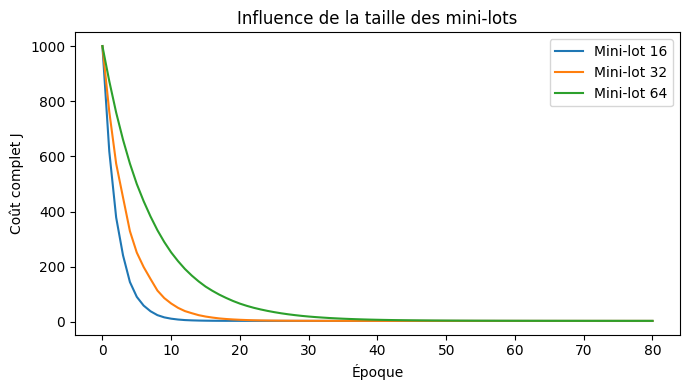

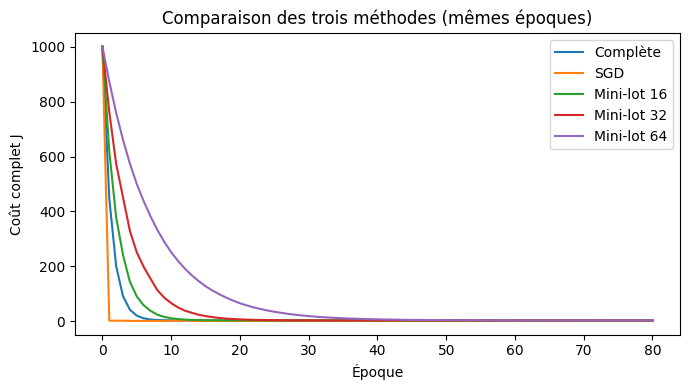

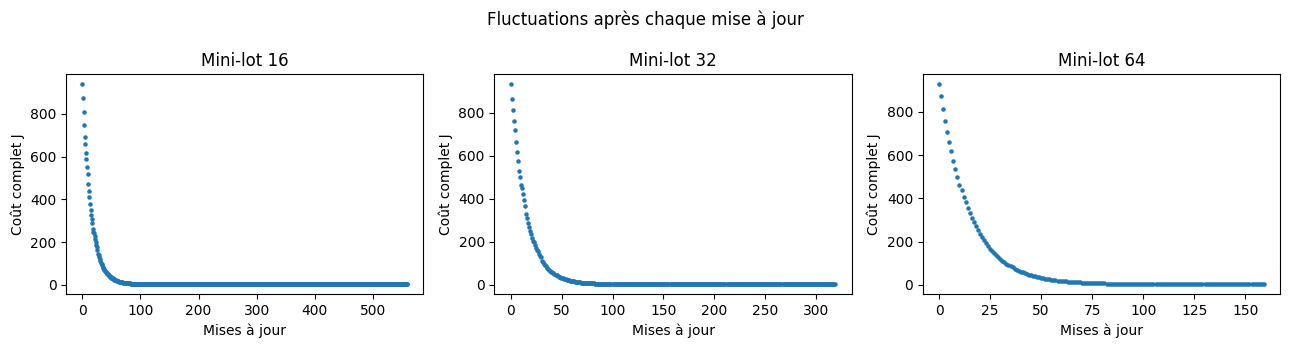

In [9]:
plt.figure(figsize=(7, 4))
for taille, resultat in resultats_lots.items():
    plt.plot(resultat[3], label=f"Mini-lot {taille}")
plt.xlabel("Époque")
plt.ylabel("Coût complet J")
plt.title("Influence de la taille des mini-lots")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(couts_batch, label="Complète")
plt.plot(couts_sgd, label="SGD")
for taille, resultat in resultats_lots.items():
    plt.plot(resultat[3], label=f"Mini-lot {taille}")
plt.xlabel("Époque")
plt.ylabel("Coût complet J")
plt.title("Comparaison des trois méthodes (mêmes époques)")
plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, taille in zip(axes, [16, 32, 64]):
    valeurs = resultats_lots[taille][4]
    ax.scatter(range(len(valeurs)), valeurs, s=5)
    ax.set_title(f"Mini-lot {taille}")
    ax.set_xlabel("Mises à jour")
    ax.set_ylabel("Coût complet J")
fig.suptitle("Fluctuations après chaque mise à jour")
fig.tight_layout()
plt.show()

## 4. Trajectoires dans l'espace des paramètres

**Questions du PDF :** représenter dans le plan $(	heta_0,	heta_1)$ les chemins de la descente complète, du SGD et d'un mini-lot. Chaque point correspond aux paramètres enregistrés **en fin d'époque**. Étiqueter chaque méthode.

Pour visualiser les variations à l'intérieur d'une époque, on pourrait aussi enregistrer les paramètres après chaque mise à jour.

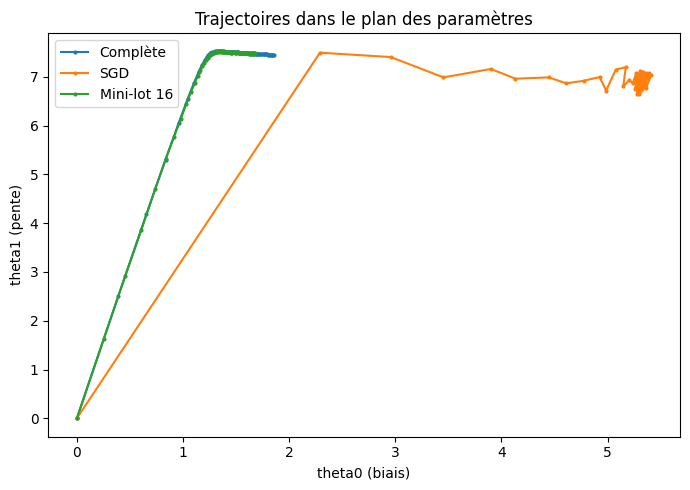

In [10]:
plt.figure(figsize=(7, 5))
for chemin, etiquette in [
    (trajectoire_batch, "Complète"),
    (trajectoire_sgd, "SGD"),
    (resultats_lots[16][2], "Mini-lot 16")
]:
    valeurs = np.asarray(chemin)
    plt.plot(valeurs[:, 0], valeurs[:, 1], "o-", markersize=2, label=etiquette)
plt.xlabel("theta0 (biais)")
plt.ylabel("theta1 (pente)")
plt.title("Trajectoires dans le plan des paramètres")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Graphiques de synthèse et comparaison

**Questions du PDF :** comparer la vitesse d'atteinte d'un **seuil de coût** et produire une *heatmap* des fluctuations.

**Attention à l'interprétation :** le nombre d'époques n'est pas le nombre de mises à jour : Batch en fait 1 par époque, SGD en fait 100 et mini-batch environ $\lceil100/B\rceil$. Les nombres d'époques mesurent le nombre de passages sur le jeu de données et non le temps de calcul.

La heatmap proposée indique, pour chaque méthode et pour chaque époque, $|J_{k}-J_{k-1}|$ : une **mesure simple des variations du coût**, pas un estimateur statistique de variance.

seuil : 2.1644638384754558
Complète min : 2.686696634086238
SGD min : 1.16480943903114
Mini-lot 16 min : 2.850604035331435
Mini-lot 32 min : 3.066149792719253
Mini-lot 64 min : 3.2257204473021
Complète : seuil non atteint
SGD : 4
Mini-lot 16 : seuil non atteint
Mini-lot 32 : seuil non atteint
Mini-lot 64 : seuil non atteint


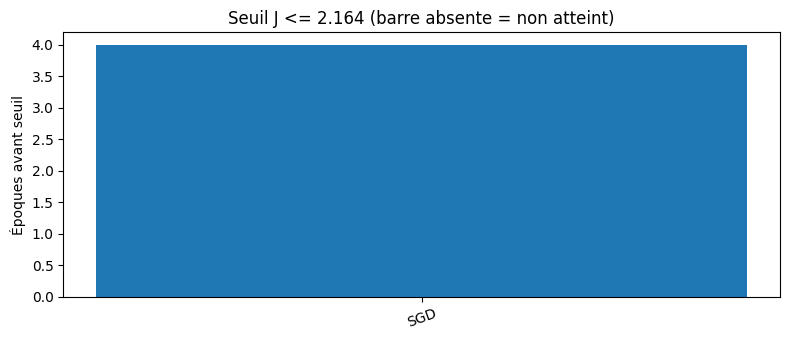

In [14]:
X = np.column_stack((np.ones(m), x_data))
solution = np.linalg.lstsq(X, y_data, rcond=None)[0]
cout_optimal = cout_lineaire(float(solution[0]), float(solution[1]))
seuil = cout_optimal + 1.0

courbes = {"Complète": couts_batch, "SGD": couts_sgd}
for taille, resultat in resultats_lots.items():
    courbes[f"Mini-lot {taille}"] = resultat[3]

# TODO : retourner l'indice de la première époque qui atteint le seuil,
# ou None si le seuil n'est jamais atteint.



def premiere_epoque_sous_seuil(couts, seuil):
   for i, c in enumerate(couts):
        if c <= seuil:
            return i
   return None

noms, epoques_atteintes = [], []
for nom, couts in courbes.items():
    epoque = premiere_epoque_sous_seuil(couts, seuil)
    print(f"{nom} : {epoque if epoque is not None else 'seuil non atteint'}")
    noms.append(nom)
    epoques_atteintes.append(np.nan if epoque is None else epoque)

plt.figure(figsize=(8, 3.5))
plt.bar(noms, epoques_atteintes)
plt.ylabel("Époques avant seuil")
plt.title(f"Seuil J <= {seuil:.3f} (barre absente = non atteint)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

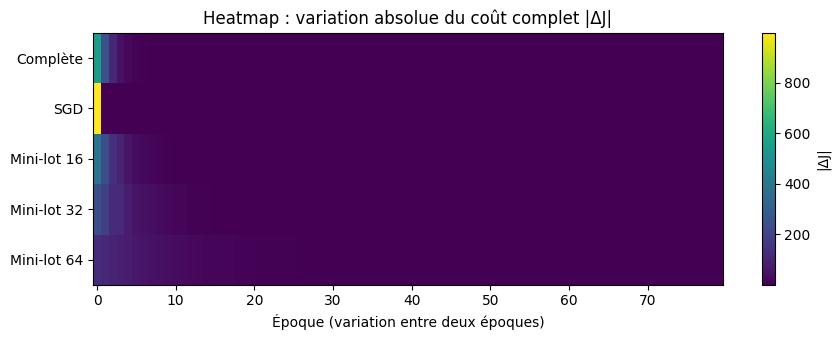

In [15]:
# Heatmap simple avec Matplotlib, sans dépendance seaborn.
variations = np.array([np.abs(np.diff(valeurs)) for valeurs in courbes.values()])
plt.figure(figsize=(9, 3.5))
plt.imshow(variations, aspect="auto", interpolation="nearest", cmap="viridis")
plt.yticks(range(len(courbes)), list(courbes.keys()))
plt.xlabel("Époque (variation entre deux époques)")
plt.title("Heatmap : variation absolue du coût complet |ΔJ|")
plt.colorbar(label="|ΔJ|")
plt.tight_layout()
plt.show()

## Questions de discussion (PDF)

1. **Vitesse et stabilité :** quelle méthode atteint le seuil le plus rapidement en nombre d'époques ? Laquelle présente les fluctuations les plus importantes ?
2. **Taille du mini-lot :** que change le passage de 16 à 32, puis 64 observations ? Pourquoi les petits lots peuvent-ils être utiles ?
3. **Application pratique :** sur un très grand jeu de données ou avec des ressources limitées, quelle méthode choisir et pourquoi ?
4. **Interprétation :** expliquez pourquoi une méthode qui atteint le seuil en moins d'époques n'est pas nécessairement la plus rapide en temps d'exécution.

**Bilan :** comparer la descente complète, SGD et mini-batch en distinguant la fréquence des mises à jour, la stabilité et le coût de calcul.